# Plant Disease Detection using 7 layer CNN
In this project we using 7 layers CNN model to train and predict plant diseases

In [10]:
# drive.flush_and_unmount()
# !rm -rf /content/drive

# !rm -rf /content/*

In [11]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)


Mounted at /content/drive


In [15]:
!unzip -q "/content/drive/MyDrive/PlantVillage_DataSet.zip" -d "/content/PlantVillage_DataSet"

In [20]:
# --- setup ---
import os, math, random, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tabulate import tabulate

# Your data path
DATA_DIR = "/content/PlantVillage_DataSet/PlantVillage_DataSet"

# --- reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)


In [21]:
# --- Class listing & weight computation ---
classes = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
num_classes = len(classes)
print(f"Total classes: {num_classes}")

class_counts = {c: len(os.listdir(os.path.join(DATA_DIR, c))) for c in classes}
print("\nClass counts:")
for c, n in class_counts.items(): print(f"{c}: {n}")

all_files, all_labels = [], []
for idx, c in enumerate(classes):
    files = [os.path.join(DATA_DIR, c, f) for f in os.listdir(os.path.join(DATA_DIR, c))]
    all_files += files
    all_labels += [idx]*len(files)

train_files, val_files, train_labels, val_labels = train_test_split(
    all_files, all_labels, test_size=0.2, stratify=all_labels, random_state=SEED
)

unique_labels = np.unique(train_labels)
weights = compute_class_weight('balanced', classes=unique_labels, y=train_labels)
class_weight_dict = dict(zip(unique_labels, weights))

table = [[c, class_weight_dict.get(i,0.0), class_counts[c]] for i,c in enumerate(classes)]
print("\nClass Weights Table:")
print(tabulate(table, headers=['Class', 'Weight', 'Count'], tablefmt='grid', floatfmt='.4f'))


Total classes: 38

Class counts:
Apple___Apple_scab: 150
Apple___Black_rot: 150
Apple___Cedar_apple_rust: 150
Apple___healthy: 150
Blueberry___healthy: 150
Cherry_(including_sour)___Powdery_mildew: 150
Cherry_(including_sour)___healthy: 150
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 150
Corn_(maize)___Common_rust_: 150
Corn_(maize)___Northern_Leaf_Blight: 150
Corn_(maize)___healthy: 150
Grape___Black_rot: 150
Grape___Esca_(Black_Measles): 150
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 150
Grape___healthy: 150
Orange___Haunglongbing_(Citrus_greening): 150
Peach___Bacterial_spot: 150
Peach___healthy: 150
Pepper,_bell___Bacterial_spot: 150
Pepper,_bell___healthy: 150
Potato___Early_blight: 150
Potato___Late_blight: 150
Potato___healthy: 150
Raspberry___healthy: 150
Soybean___healthy: 150
Squash___Powdery_mildew: 150
Strawberry___Leaf_scorch: 150
Strawberry___healthy: 150
Tomato___Bacterial_spot: 150
Tomato___Early_blight: 150
Tomato___Late_blight: 150
Tomato___Leaf_Mold: 150
Tom

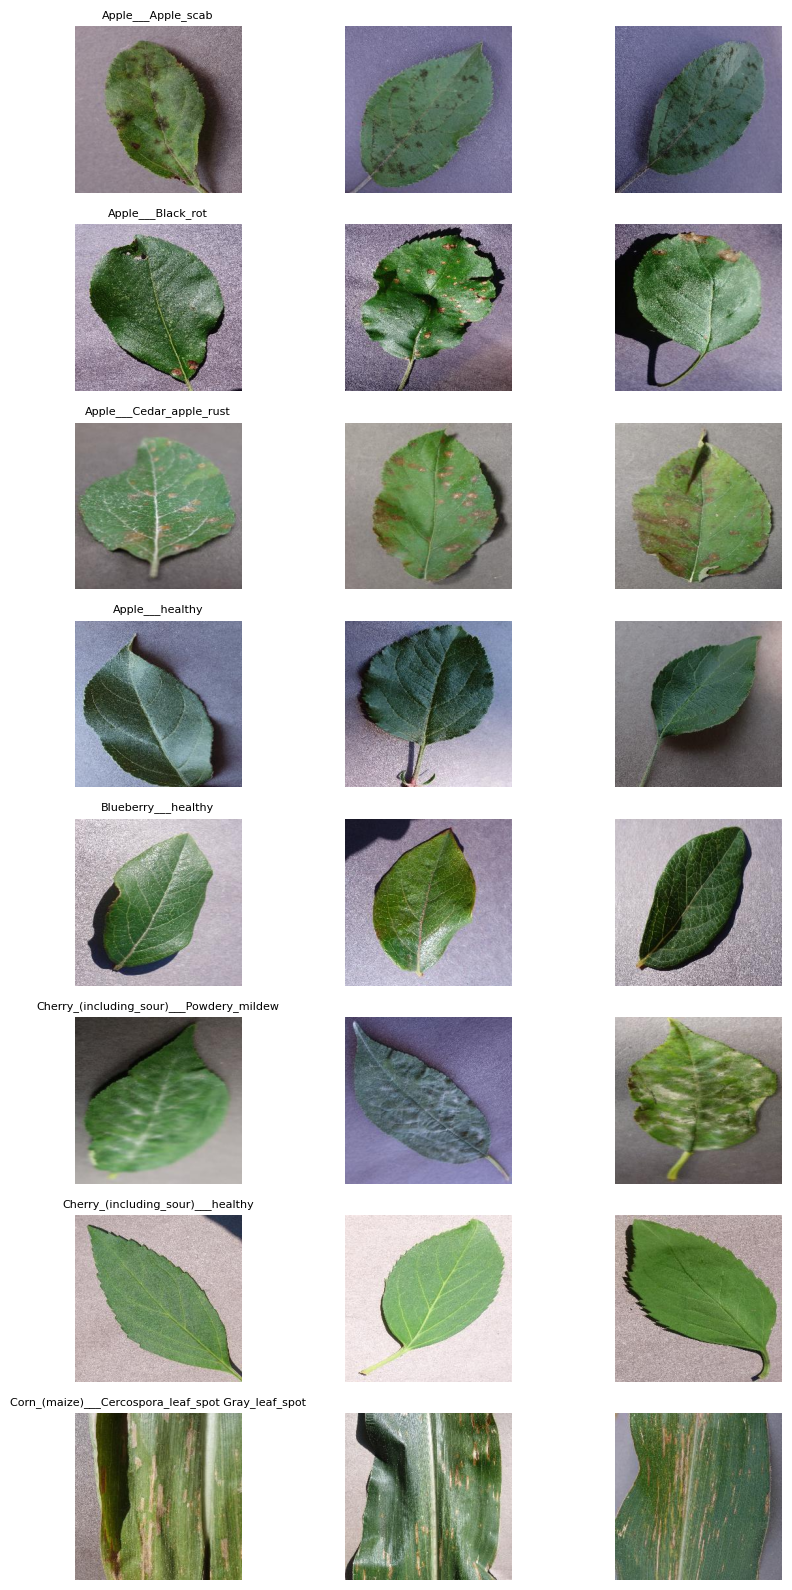

In [36]:

def plot_samples(classes, n_per_class=3):
    plt.figure(figsize=(n_per_class*3, len(classes)*2))
    i = 1
    for idx, c in enumerate(classes):
        imgs = os.listdir(os.path.join(DATA_DIR, c))
        samples = random.sample(imgs, min(n_per_class, len(imgs)))
        for s in samples:
            path = os.path.join(DATA_DIR, c, s)
            try:
                im = Image.open(path).convert("RGB")
                plt.subplot(len(classes), n_per_class, i)
                plt.imshow(im)
                plt.axis("off")
                if i % n_per_class == 1:
                    plt.title(c, fontsize=8)
                i += 1
            except Exception as e:
                print("Error loading", path, e)
    plt.tight_layout()
    plt.show()

plot_samples(classes[:8], n_per_class=3)

Found 4560 images belonging to 38 classes.
Found 1140 images belonging to 38 classes.
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tom

Model: "plant_disease_cnn7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv1 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn1 (BatchNormalization)     │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu1 (Activation)           │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv2 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn2 (BatchNormalization)     │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu2 (Activation)           │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_drop (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn1 (BatchNormalization)     │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu1 (Activation)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv2 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn2 (BatchNormalization)     │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu2 (Activation)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_drop (Dropout)               │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv1 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn1 (BatchNormalization)     │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu1 (Activation)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv2 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn2 (BatchNormalization)     │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu2 (Activation)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_pool (MaxPooling2D)          │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_drop (Dropout)               │ (None, 28, 28, 128)    │             

 Total params: 622,790 (2.38 MB)

 Trainable params: 621,382 (2.37 MB)

 Non-trainable params: 1,408 (5.50 KB)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.1298 - loss: 3.4068
Epoch 1: val_loss improved from inf to 5.23448, saving model to /content/plant_disease_cnn7_best.keras
143/143 ━━━━━━━━━━━━━━━━━━━━ 69s 299ms/step - accuracy: 0.1302 - loss: 3.4041 - val_accuracy: 0.0465 - val_loss: 5.2345 - learning_rate: 0.0010
Epoch 2/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.3492 - loss: 2.3612
Epoch 2: val_loss did not improve from 5.23448
143/143 ━━━━━━━━━━━━━━━━━━━━ 23s 162ms/step - accuracy: 0.3494 - loss: 2.3604 - val_accuracy: 0.0518 - val_loss: 7.6127 - learning_rate: 0.0010
Epoch 3/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.4399 - loss: 1.9812
Epoch 3: val_loss did not improve from 5.23448
143/143 ━━━━━━━━━━━━━━━━━━━━ 24s 166ms/step - accuracy: 0.4401 - loss: 1.9805 - val_accuracy: 0.0807 - val_loss: 7.1843 - learning_rate: 0.0010
Epoch 4/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.5328 - loss: 1.6592
Epoch 4: val_loss i

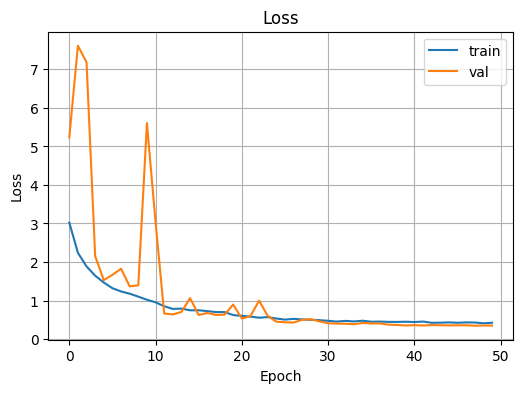

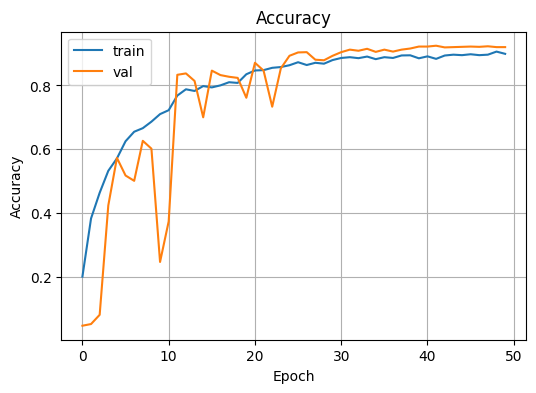

36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    0.9000    0.9474        30
                                 Apple___Black_rot     0.9667    0.9667    0.9667        30
                          Apple___Cedar_apple_rust     0.9677    1.0000    0.9836        30
                                   Apple___healthy     0.9062    0.9667    0.9355        30
                               Blueberry___healthy     0.9355    0.9667    0.9508        30
          Cherry_(including_sour)___Powdery_mildew     1.0000    0.9333    0.9655        30
                 Cherry_(including_sour)___healthy     0.9375    1.0000    0.9677        30
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9545    0.7000    0.8077        30
                       Corn_(maize)___Common_rust_     0.9677    1.0000    0.9836        30
               

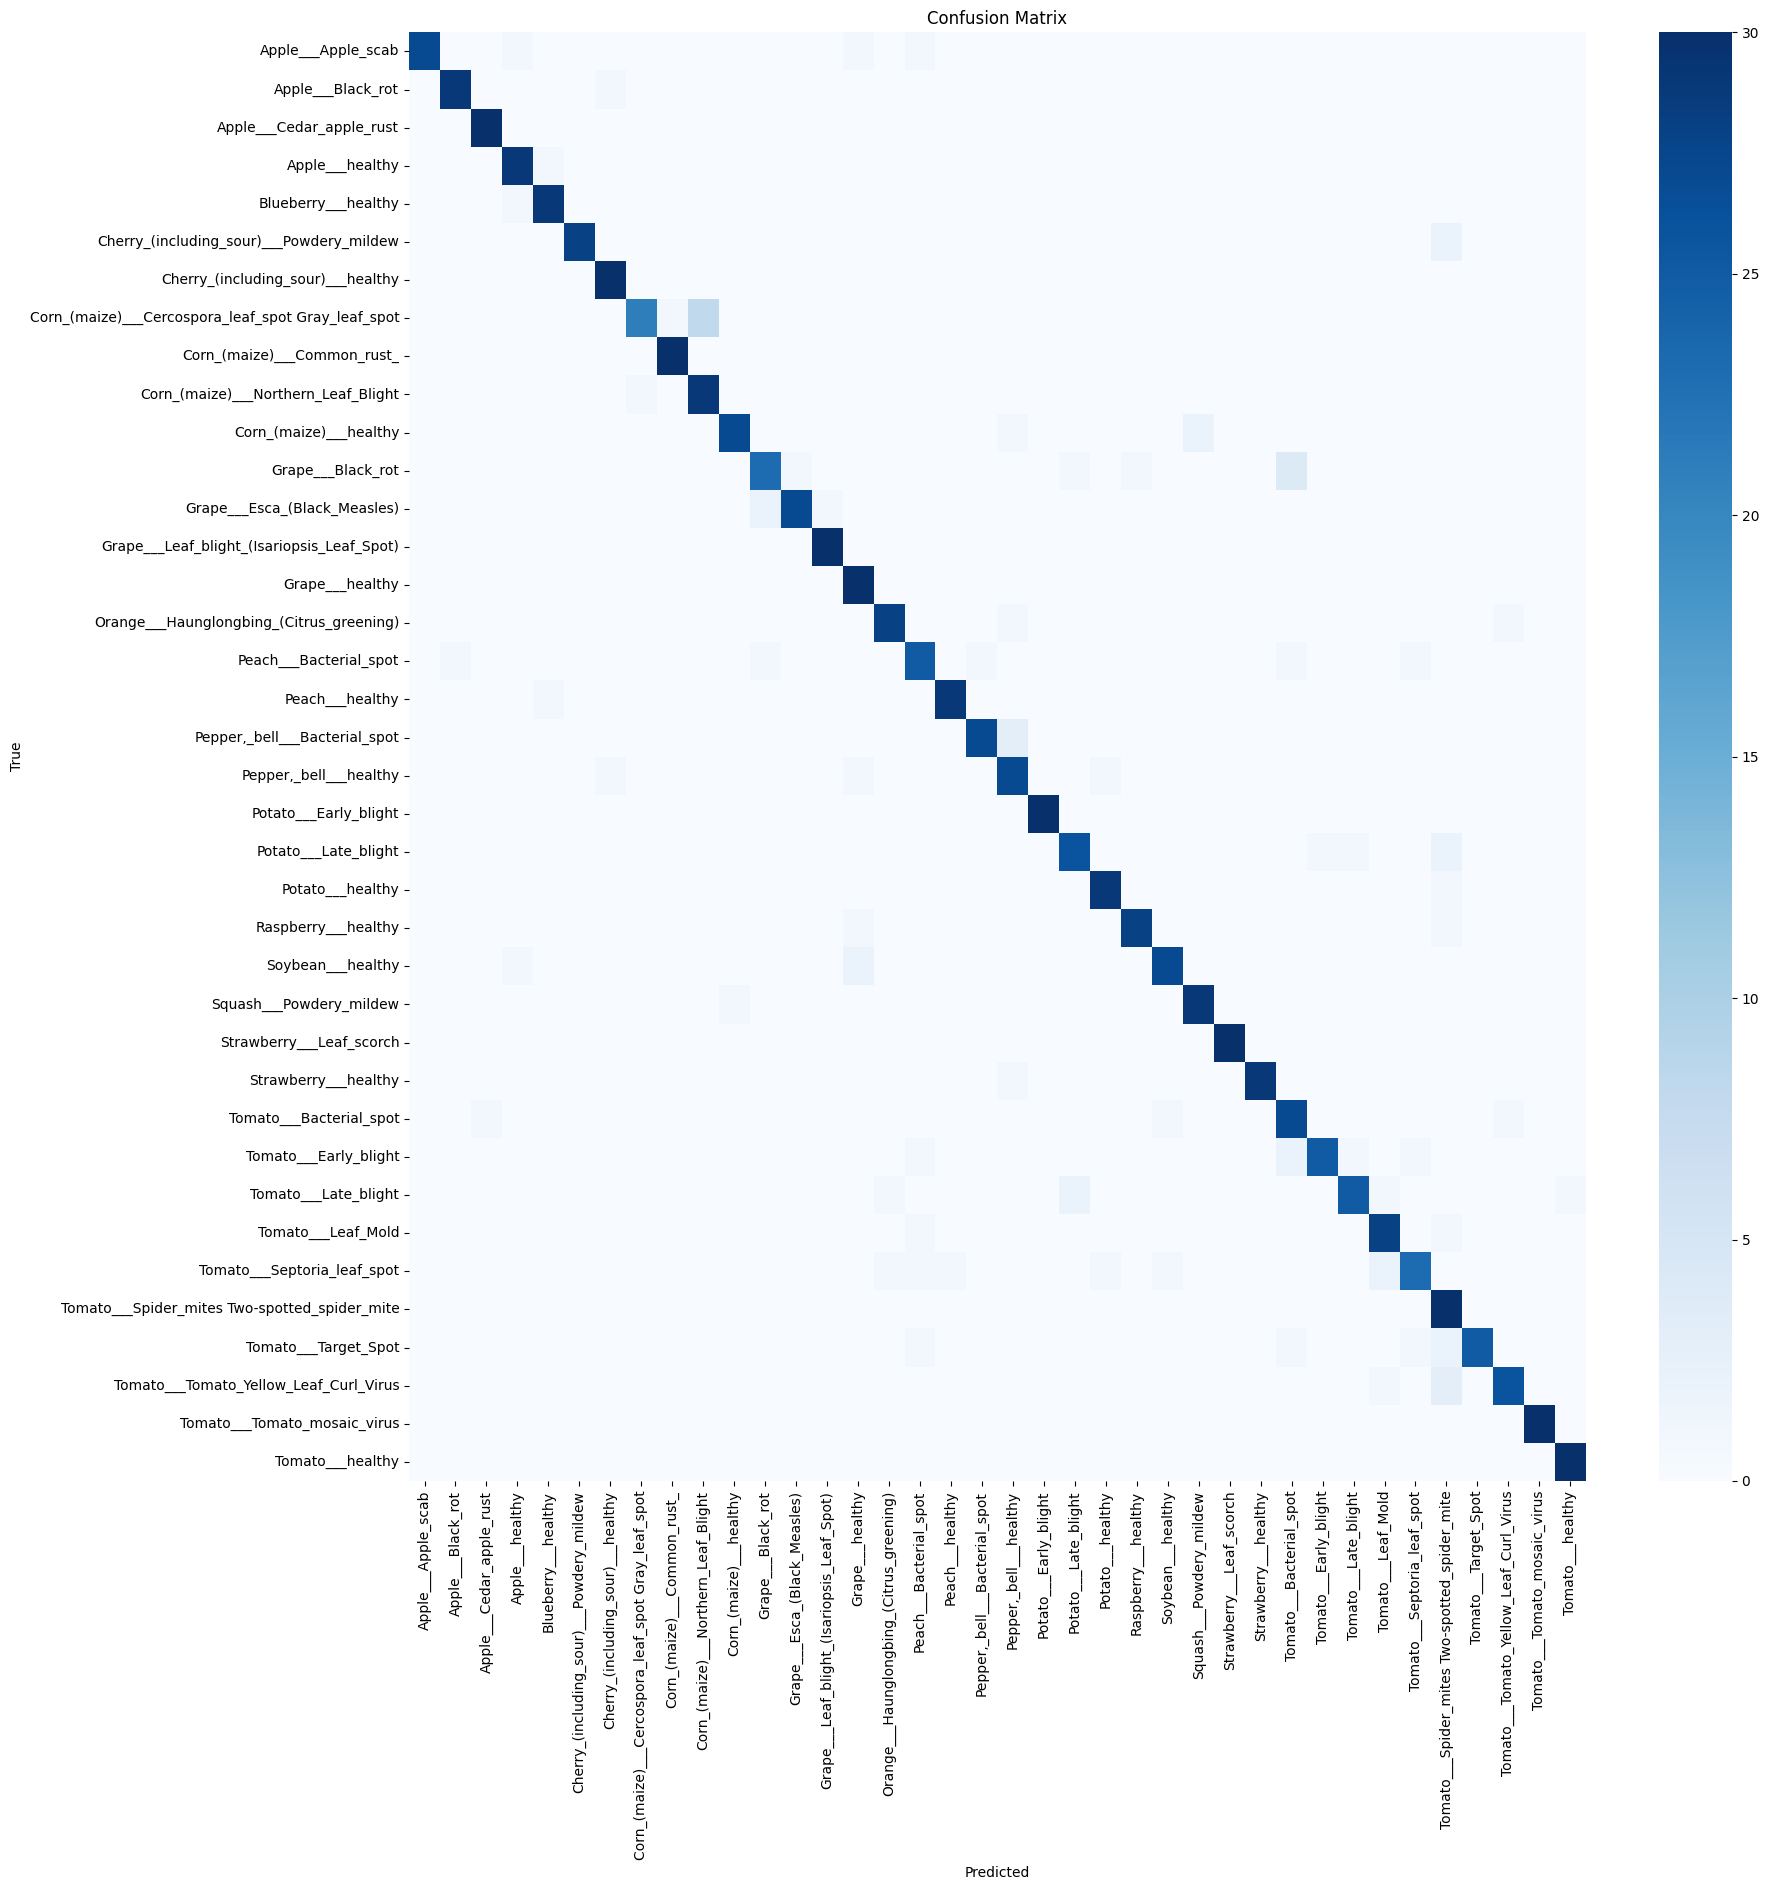

Saved: /content/plant_disease_cnn7_best.keras and /content/class_indices.json


In [17]:
# --- config ---
IMG_SIZE = (224, 224)    # good balance of speed/accuracy
BATCH_SIZE = 32
VAL_SPLIT = 0.20
L2 = 1e-4
DROPOUT = 0.25
INIT_LR = 1e-3
EPOCHS = 50
MODEL_PATH = "/content/plant_disease_cnn7_best.keras"

train_aug = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    brightness_range=(0.9, 1.2)
)


valid_aug = ImageDataGenerator(
    rescale=1./255,
    validation_split=VAL_SPLIT
)

train_gen = train_aug.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=SEED
)

val_gen = valid_aug.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

num_classes = train_gen.num_classes
class_names = list(train_gen.class_indices.keys())
print("Classes:", class_names)

# --- class weights (helps with imbalance) ---
y_train = train_gen.classes
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {i: w for i, w in enumerate(class_weights_arr)}
print("Class weights:", class_weights)

# --- 7-layer CNN (7 conv layers total) ---
# Block layout: (Conv,Conv) x3 + (Conv) x1 = 7
def conv_block(filters, name_prefix, convs=2):
    blk = []
    for i in range(convs):
        blk += [
            layers.Conv2D(filters, (3,3), padding="same",
                          kernel_regularizer=regularizers.l2(L2),
                          name=f"{name_prefix}_conv{i+1}"),
            layers.BatchNormalization(name=f"{name_prefix}_bn{i+1}"),
            layers.Activation("relu", name=f"{name_prefix}_relu{i+1}"),
        ]
    blk += [
        layers.MaxPooling2D(pool_size=(2,2), name=f"{name_prefix}_pool"),
        layers.Dropout(DROPOUT, name=f"{name_prefix}_drop")
    ]
    return blk

inputs = layers.Input(shape=(*IMG_SIZE, 3), name="input")

x = inputs
# Block 1: 2 convs
for layer in conv_block(32, "b1", convs=2): x = layer(x)
# Block 2: 2 convs
for layer in conv_block(64, "b2", convs=2): x = layer(x)
# Block 3: 2 convs
for layer in conv_block(128, "b3", convs=2): x = layer(x)
# Block 4: 1 conv (this is the 7th conv)
x = layers.Conv2D(256, (3,3), padding="same",
                  kernel_regularizer=regularizers.l2(L2),
                  name="b4_conv1")(x)
x = layers.BatchNormalization(name="b4_bn1")(x)
x = layers.Activation("relu", name="b4_relu1")(x)
x = layers.MaxPooling2D(pool_size=(2,2), name="b4_pool")(x)
x = layers.Dropout(DROPOUT, name="b4_drop")(x)

# Head
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(L2), name="fc1")(x)
x = layers.Dropout(0.4, name="fc_drop")(x)
outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

model = keras.Model(inputs, outputs, name="plant_disease_cnn7")
model.summary()

# --- compile ---
optimizer = keras.optimizers.Adam(learning_rate=INIT_LR)
model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# --- callbacks ---
early = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)
plateau = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)
ckpt = ModelCheckpoint(
    MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# --- train ---
history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    class_weight=class_weights,
    callbacks=[early, plateau, ckpt],
    verbose=1
)

# --- load best (safety) ---
model = keras.models.load_model(MODEL_PATH)

# --- metrics & plots ---
# learning curves
plt.figure(figsize=(6,4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(True)
plt.show()

# predictions & confusion matrix
val_gen.reset()
probs = model.predict(val_gen, verbose=1)
y_pred = probs.argmax(axis=1)
y_true = val_gen.classes

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(8, len(class_names)*0.5), max(6, len(class_names)*0.5)))
sns.heatmap(cm, annot=False, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
plt.show()

# save label map
with open("/content/class_indices.json", "w") as f:
    json.dump(train_gen.class_indices, f, indent=2)
print("Saved:", MODEL_PATH, "and /content/class_indices.json")


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# overall statistical measures
accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
recall_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
precision_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print("\n📈 Overall Statistical Measures:")
print(tabulate([
    ["Accuracy", accuracy],
    ["Precision (macro)", precision_macro],
    ["Recall (macro)", recall_macro],
    ["F1-score (macro)", f1_macro],
    ["Precision (weighted)", precision_weighted],
    ["Recall (weighted)", recall_weighted],
    ["F1-score (weighted)", f1_weighted],
], headers=["Metric", "Value"], floatfmt=".4f"))



📈 Overall Statistical Measures:
Metric                  Value
--------------------  -------
Accuracy               0.9228
Precision (macro)      0.9281
Recall (macro)         0.9228
F1-score (macro)       0.9227
Precision (weighted)   0.9281
Recall (weighted)      0.9228
F1-score (weighted)    0.9227


In [25]:
# --- Per-class accuracy from confusion matrix ---
cm_sum = np.sum(cm, axis=1, keepdims=True)
cm_perc = cm.astype('float') / cm_sum * 100
per_class_acc = np.diag(cm_perc)

results_table = pd.DataFrame({
    "Class": class_names,
    "Accuracy (%)": per_class_acc.round(2)
}).sort_values("Accuracy (%)", ascending=False)

print("\n🔍 Per-Class Accuracy:")
print(tabulate(results_table.values, headers=results_table.columns, tablefmt="grid"))



🔍 Per-Class Accuracy:
+----------------------------------------------------+----------------+
| Class                                              |   Accuracy (%) |
+====================================================+================+
| Apple___Cedar_apple_rust                           |         100    |
+----------------------------------------------------+----------------+
| Potato___Early_blight                              |         100    |
+----------------------------------------------------+----------------+
| Grape___healthy                                    |         100    |
+----------------------------------------------------+----------------+
| Grape___Leaf_blight_(Isariopsis_Leaf_Spot)         |         100    |
+----------------------------------------------------+----------------+
| Corn_(maize)___Common_rust_                        |         100    |
+----------------------------------------------------+----------------+
| Cherry_(including_sour)___healthy      

/tmp/ipython-input-2627731994.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Accuracy (%)", y="Class", data=results_table, palette="crest")


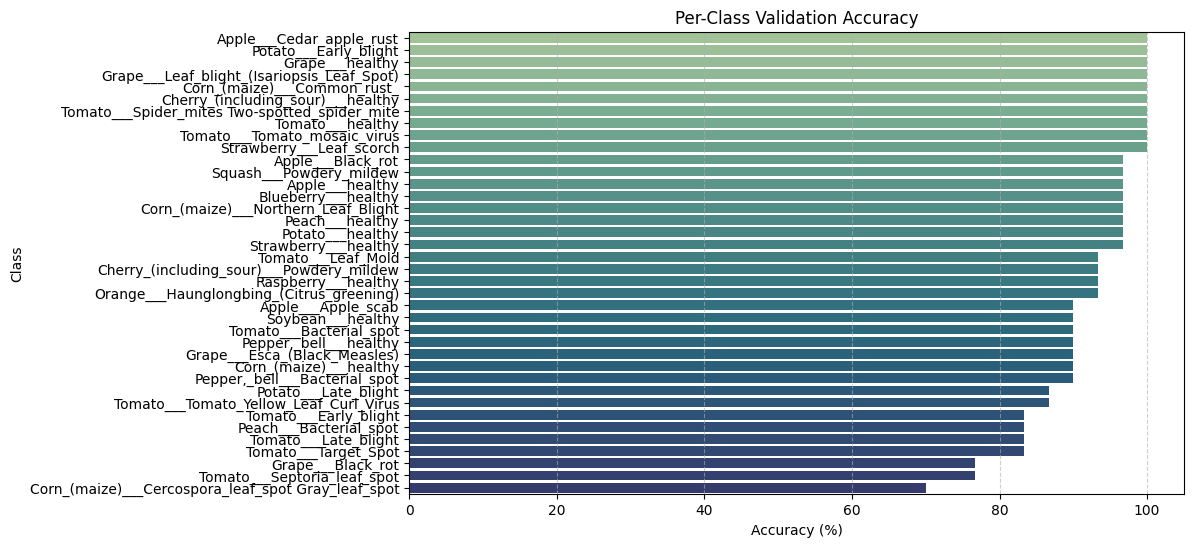

In [26]:

plt.figure(figsize=(10,6))
sns.barplot(x="Accuracy (%)", y="Class", data=results_table, palette="crest")
plt.title("Per-Class Validation Accuracy")
plt.xlabel("Accuracy (%)"); plt.ylabel("Class")
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.show()


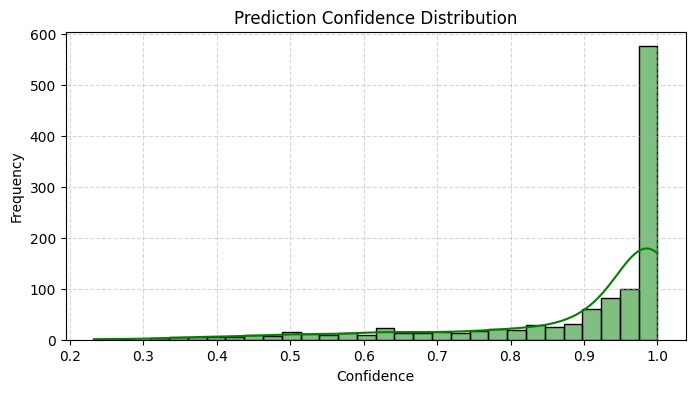


Average confidence: 0.894
Standard deviation: 0.160


In [27]:
# --- Confidence analysis ---
confidences = np.max(probs, axis=1)
plt.figure(figsize=(8,4))
sns.histplot(confidences, bins=30, kde=True, color='green')
plt.title("Prediction Confidence Distribution")
plt.xlabel("Confidence"); plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"\nAverage confidence: {np.mean(confidences):.3f}")
print(f"Standard deviation: {np.std(confidences):.3f}")



❌ Misclassified samples: 88 out of 1140


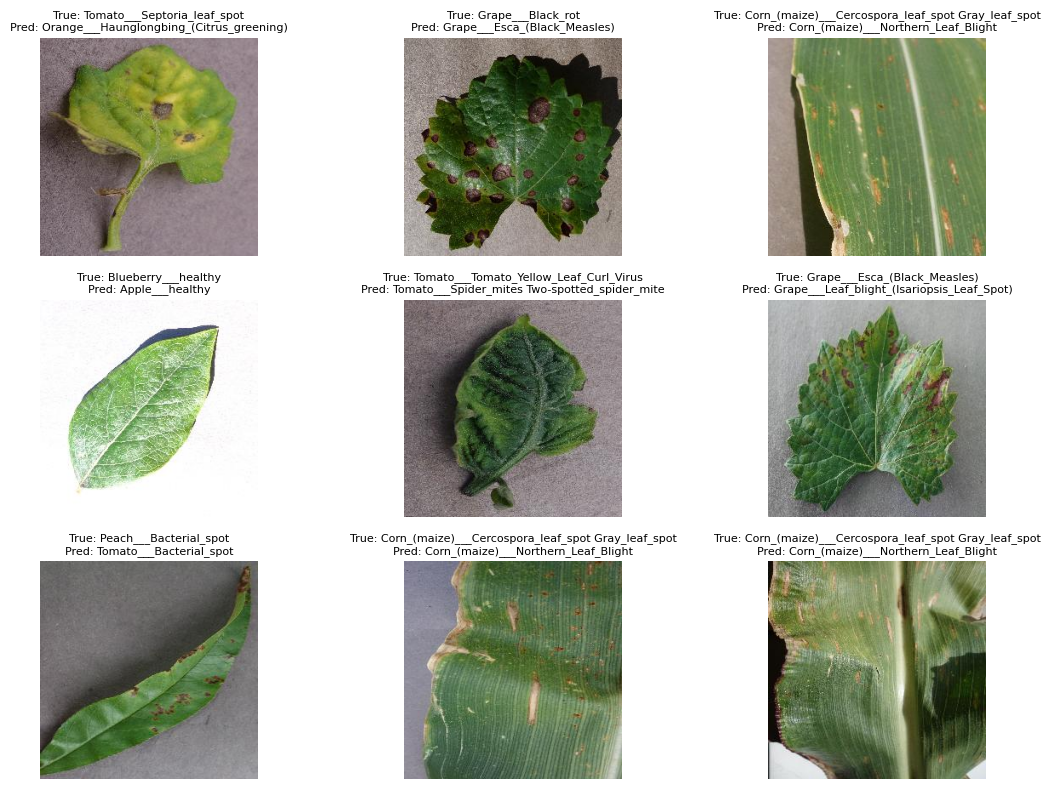

In [28]:
# --- Show sample misclassifications ---
val_paths = val_gen.filepaths
mis_idx = np.where(y_true != y_pred)[0]

print(f"\n❌ Misclassified samples: {len(mis_idx)} out of {len(y_true)}")

if len(mis_idx) > 0:
    sample_errors = random.sample(list(mis_idx), min(9, len(mis_idx)))
    plt.figure(figsize=(12,8))
    for i, idx in enumerate(sample_errors):
        img = Image.open(val_paths[idx])
        plt.subplot(3,3,i+1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=8)
    plt.tight_layout()
    plt.show()


In [29]:
# --- Model stats summary ---
params = model.count_params()
file_size_mb = os.path.getsize(MODEL_PATH) / (1024*1024)

print("\n📦 Model Summary:")
print(f"Total Parameters: {params:,}")
print(f"Saved Model Size: {file_size_mb:.2f} MB")

import time
start = time.time()
_ = model.predict(np.zeros((1,224,224,3)))
end = time.time()
print(f"Inference time per image: {(end - start)*1000:.2f} ms")



📦 Model Summary:
Total Parameters: 622,790
Saved Model Size: 7.25 MB
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Inference time per image: 1602.64 ms


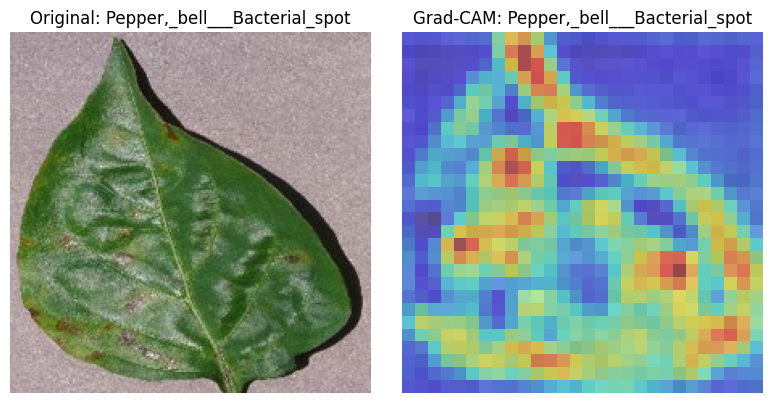

In [31]:
# --- Grad-CAM Visualization ---
import tensorflow as tf

def get_gradcam(model, img_array, layer_name):
    grad_model = tf.keras.models.Model([model.inputs], [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        class_idx = tf.argmax(predictions[0])
        loss = predictions[:, class_idx]
    grads = tape.gradient(loss, conv_outputs)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = np.zeros(conv_outputs.shape[1:3], dtype=np.float32)
    for i, w in enumerate(weights):
        cam += w * conv_outputs[0, :, :, i]
    cam = np.maximum(cam, 0)
    cam = cam / cam.max()
    return cam, int(class_idx)

# Pick a random validation image
sample_idx = random.choice(range(len(val_gen.filepaths)))
sample_path = val_gen.filepaths[sample_idx]
img = Image.open(sample_path).resize(IMG_SIZE)
x = np.expand_dims(np.array(img)/255.0, axis=0)

cam, class_idx = get_gradcam(model, x, layer_name="b4_conv1")
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(img)
plt.axis('off')
plt.title(f"Original: {class_names[y_true[sample_idx]]}")

plt.subplot(1,2,2)
plt.imshow(img)
plt.imshow(cam, cmap='jet', alpha=0.5)
plt.axis('off')
plt.title(f"Grad-CAM: {class_names[class_idx]}")
plt.tight_layout()
plt.show()


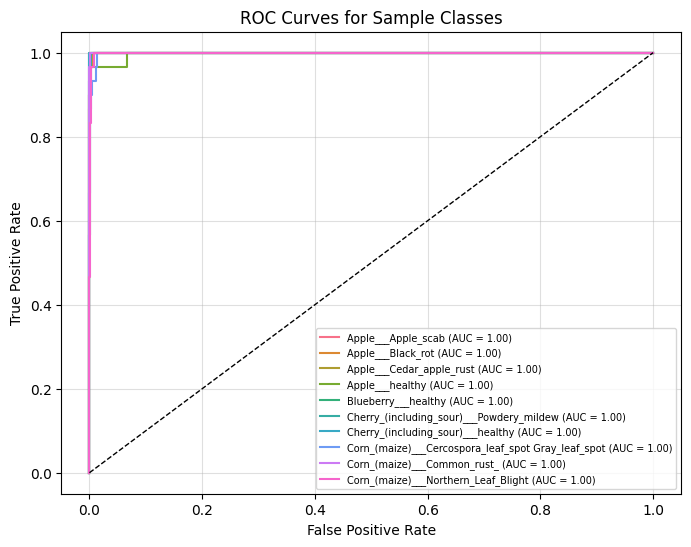

In [32]:
# --- Multi-class ROC curve visualization ---
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle

# Binarize labels for ROC
y_true_bin = label_binarize(y_true, classes=np.arange(num_classes))
fpr, tpr, roc_auc = {}, {}, {}
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot few ROC curves
plt.figure(figsize=(8,6))
colors = cycle(sns.color_palette("husl", 10))
for i, color in zip(range(min(10, num_classes)), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=1.5,
             label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0,1],[0,1],'k--',lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Sample Classes')
plt.legend(fontsize=7)
plt.grid(True, alpha=0.4)
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step


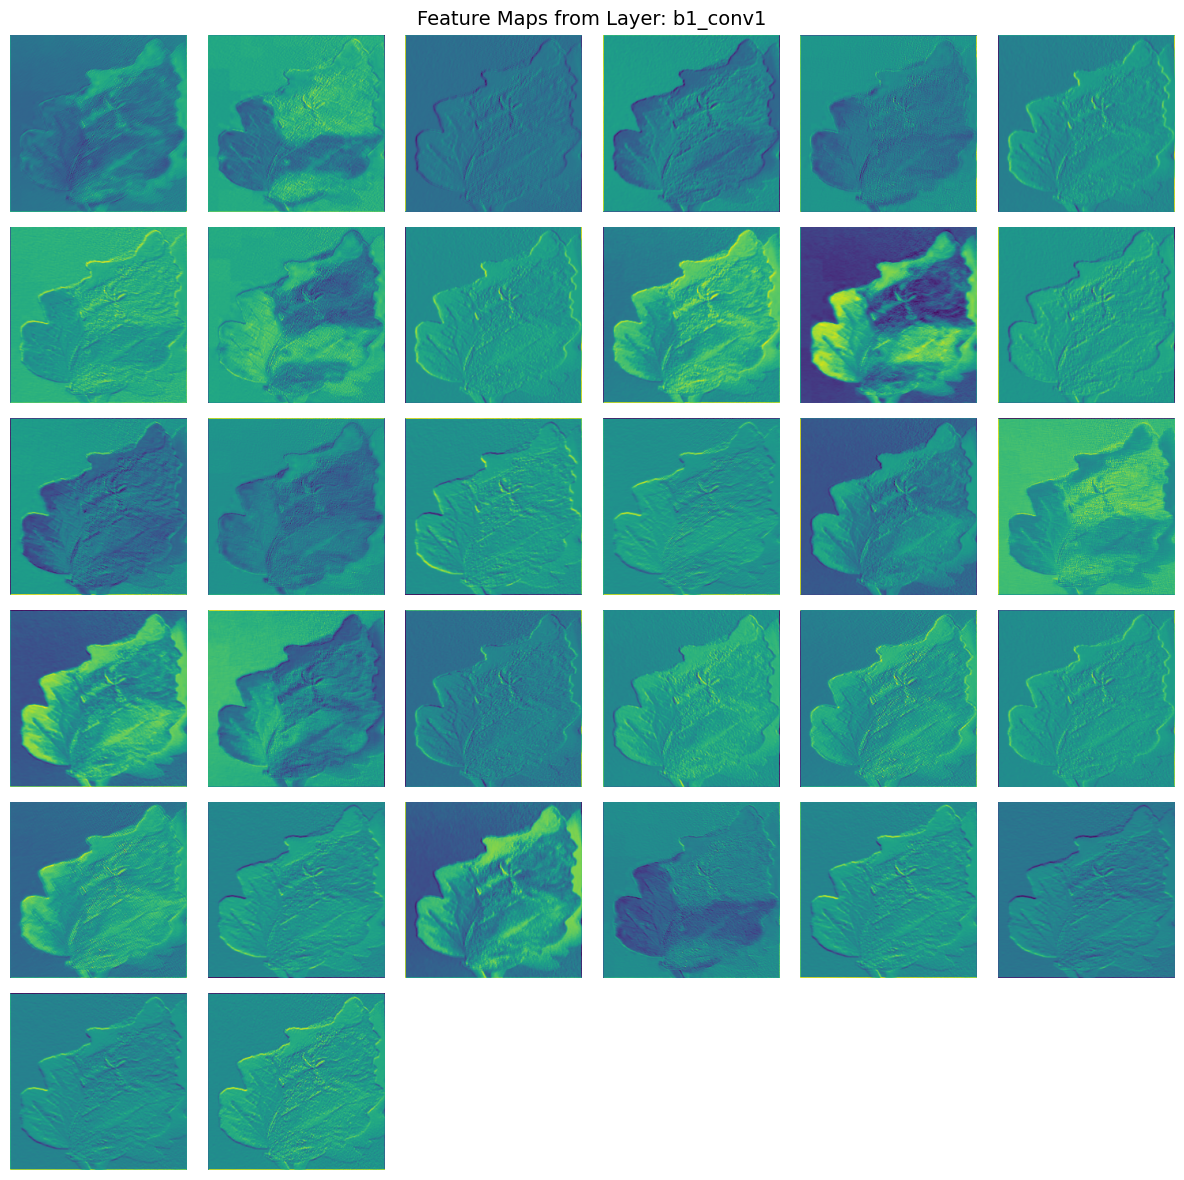

In [34]:
# --- Visualize feature maps from an intermediate layer ---
from tensorflow.keras import models

layer_name = 'b1_conv1'
intermediate_model = models.Model(inputs=model.input, outputs=model.get_layer(layer_name).output)

img_path = random.choice(val_gen.filepaths)
img = Image.open(img_path).resize(IMG_SIZE)
x = np.expand_dims(np.array(img)/255.0, axis=0)
feature_maps = intermediate_model.predict(x)

square = int(np.ceil(np.sqrt(feature_maps.shape[-1])))
plt.figure(figsize=(12,12))
for i in range(min(64, feature_maps.shape[-1])):
    plt.subplot(square, square, i+1)
    plt.imshow(feature_maps[0,:,:,i], cmap='viridis')
    plt.axis('off')
plt.suptitle(f'Feature Maps from Layer: {layer_name}', fontsize=14)
plt.tight_layout()
plt.show()


In [35]:
# --- Convert model to TFLite for mobile apps ---
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
open("/content/plant_disease_cnn7.tflite", "wb").write(tflite_model)
print("Model exported as TFLite for mobile deployment.")


Saved artifact at '/tmp/tmposll23yu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input')
Output Type:
  TensorSpec(shape=(None, 38), dtype=tf.float32, name=None)
Captures:
  138214854530384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138212522723664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138212522737488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138212559041936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138212559044432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138212522721360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138212559041168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138212559044240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138210658566992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138210658567952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138210658567760: Ten